In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


In [2]:
class SortDataset(Dataset):
    def __init__(self, seq_len=64, num_samples=100000):
        self.seq_len = seq_len
        self.num_samples = num_samples
        number = torch.rand(num_samples, seq_len)
        argsort = torch.argsort(number, dim=1)
        argsort_till_t = torch.zeros(num_samples, seq_len, seq_len)
        for i in range(seq_len):
            argsort_till_t[:, i, :i+1] = torch.argsort(number[:, :i+1], dim=1, descending=False)
            argsort_till_t[:, i, i+1:] = -11  # padding with -1
        self.argsort_till_t = argsort_till_t.to(torch.long)
        self.data = number.unsqueeze(-1)
        self.target = argsort
        self.input_size = 1
        self.output_size = seq_len**2

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.target[idx]

# Create datasets
seq_len = 5
train_dataset = SortDataset(seq_len=seq_len, num_samples=50000)
test_dataset = SortDataset(seq_len=seq_len, num_samples=1000)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example
sample_input, sample_target = train_dataset[0]
print(f"\nExample input shape: {sample_input}")
print(f"Example target: {sample_target}")

Training dataset size: 50000
Test dataset size: 1000

Example input shape: tensor([[0.5766],
        [0.2375],
        [0.9321],
        [0.4711],
        [0.4220]])
Example target: tensor([1, 4, 3, 0, 2])


In [3]:
device='cuda:0'
batch_size = 64
hidden_size = 64
input_size = train_dataset.input_size  # [number, indicator]
output_size = train_dataset.output_size  # regression output
simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
net_path = './model/sort/ei_net.pth'
simple_net_path = './model/sort/simple_net.pth'
net.load_state_dict(torch.load(net_path))
simple_net.load_state_dict(torch.load(simple_net_path))

<All keys matched successfully>

Collect Data


In [4]:
def get_data(net, simple_net):
    n_trial = 100
    h_all = np.zeros((n_trial, seq_len, batch_size, hidden_size))
    h_simple = np.zeros((n_trial, seq_len, batch_size, hidden_size))
    input_all = np.zeros((n_trial, seq_len, batch_size, input_size))
    target_all = np.zeros((n_trial, batch_size, seq_len))
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    loader = iter(train_loader)
    for i in range(n_trial):
        inputs, targets = next(loader)
        # for batch_inputs, batch_targets in train_loader:
        try:
            batch_inputs, batch_targets = next(loader)
        except StopIteration:
            train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
            loader = iter(train_loader)
            batch_inputs, batch_targets = next(loader)
        batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
        # print('batch_inputs:', batch_inputs.shape)
        batch_targets = batch_targets.to(device)  # (batch_size, seq_len)
        B, T = batch_targets.shape

        # Forward pass
        net_outputs, net_eimask_logit, net_hidden = net(batch_inputs)
        simple_outputs, simple_eimask_logit, simple_hidden = simple_net(batch_inputs)
        h_all[i] = net_hidden[0].detach().cpu().numpy()
        h_simple[i] = simple_hidden[0].detach().cpu().numpy()
        input_all[i] = batch_inputs.detach().cpu().numpy()
        target_all[i] = batch_targets.detach().cpu().numpy()
    print('h_all:', h_all.shape)
    h_all = h_all.transpose(0,2,1,3).reshape(-1, seq_len, hidden_size)  # (time, l, hidden_size)
    h_simple = h_simple.transpose(0,2,1,3).reshape(-1, seq_len, hidden_size)  # (time, l, hidden_size)
    input_all = input_all.transpose(0,2,1,3).reshape(-1, seq_len, input_size)  # (time, l, input_size)
    target_all = target_all.reshape(-1, seq_len)  # (l, seq_len)
    return h_all, h_simple, input_all, target_all
h_all, h_simple, input_all, target_all = get_data(net, simple_net)
print('h_all:', h_all.shape, 'input_all:', input_all.shape, 'target_all:', target_all.shape)

h_all: (100, 5, 64, 64)
h_all: (6400, 5, 64) input_all: (6400, 5, 1) target_all: (6400, 5)


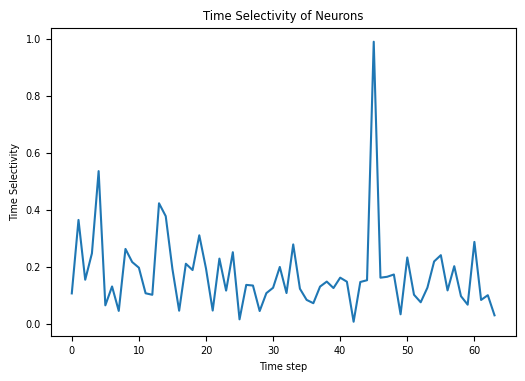

Time selective neurons: [45  4 13 14  1]
input: [0.16525233 0.26675403 0.90697384 0.55673754 0.19954377] target: [0. 4. 1. 3. 2.]


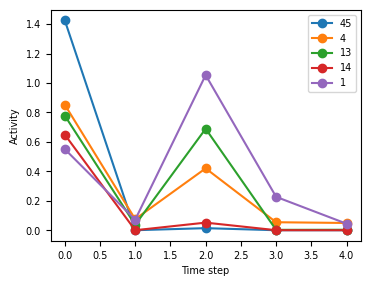

input: [0.05052608 0.61952579 0.74054497 0.47474957 0.80820894] target: [0. 3. 1. 2. 4.]


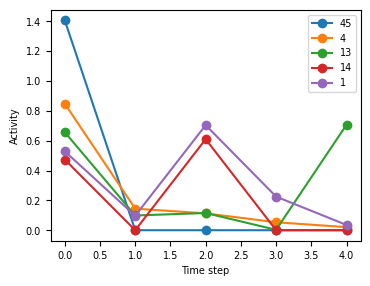

input: [0.71765071 0.04637498 0.34019458 0.4926734  0.04341561] target: [4. 1. 2. 3. 0.]


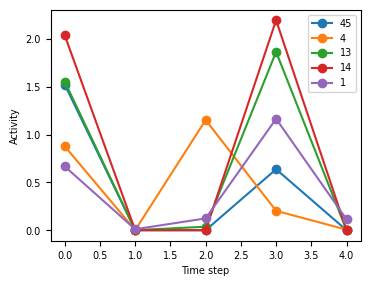

input: [0.95407659 0.21112555 0.61392224 0.27100033 0.33536315] target: [1. 3. 4. 2. 0.]


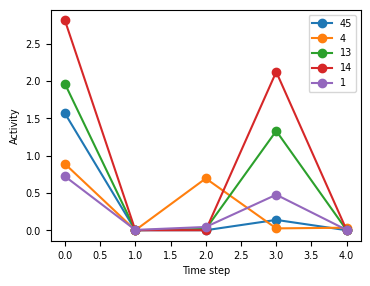

input: [0.11597729 0.21139771 0.78228307 0.02394354 0.64837474] target: [3. 0. 1. 4. 2.]


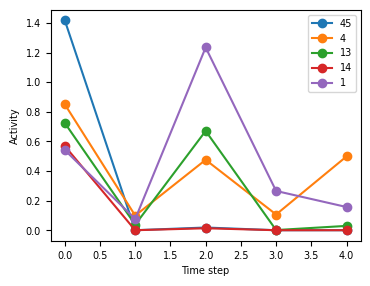

In [5]:
time_selectivity = h_all.mean(0).var(0)/h_all.var(axis=(0,1))
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(time_selectivity)
ax.set_xlabel('Time step')
ax.set_ylabel('Time Selectivity')
ax.set_title('Time Selectivity of Neurons')
plt.show()
time_selective_neurons = np.argsort(-time_selectivity)[:5]
print('Time selective neurons:', time_selective_neurons)
plt.close()
for i in range(5):
    fig, ax = plt.subplots(1,1, figsize=(4,3))
    idx = np.random.randint(h_all.shape[0])
    print('input:', input_all[idx].squeeze(), 'target:', target_all[idx])
    for j in range(5):
        ax.plot(h_all[idx, :, time_selective_neurons[j]], marker='o', label=time_selective_neurons[j])
    ax.legend()
    ax.set_xlabel('Time step')
    ax.set_ylabel('Activity')
    plt.show()
    plt.close()

Position / Ranking selectivity


Net:


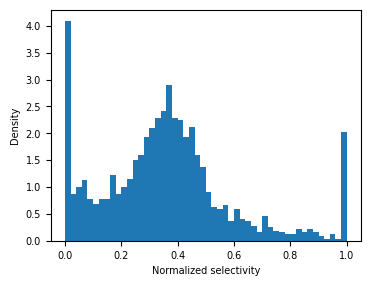

specificity_index: 0.8131249999999999 +- 0.12590764224224038


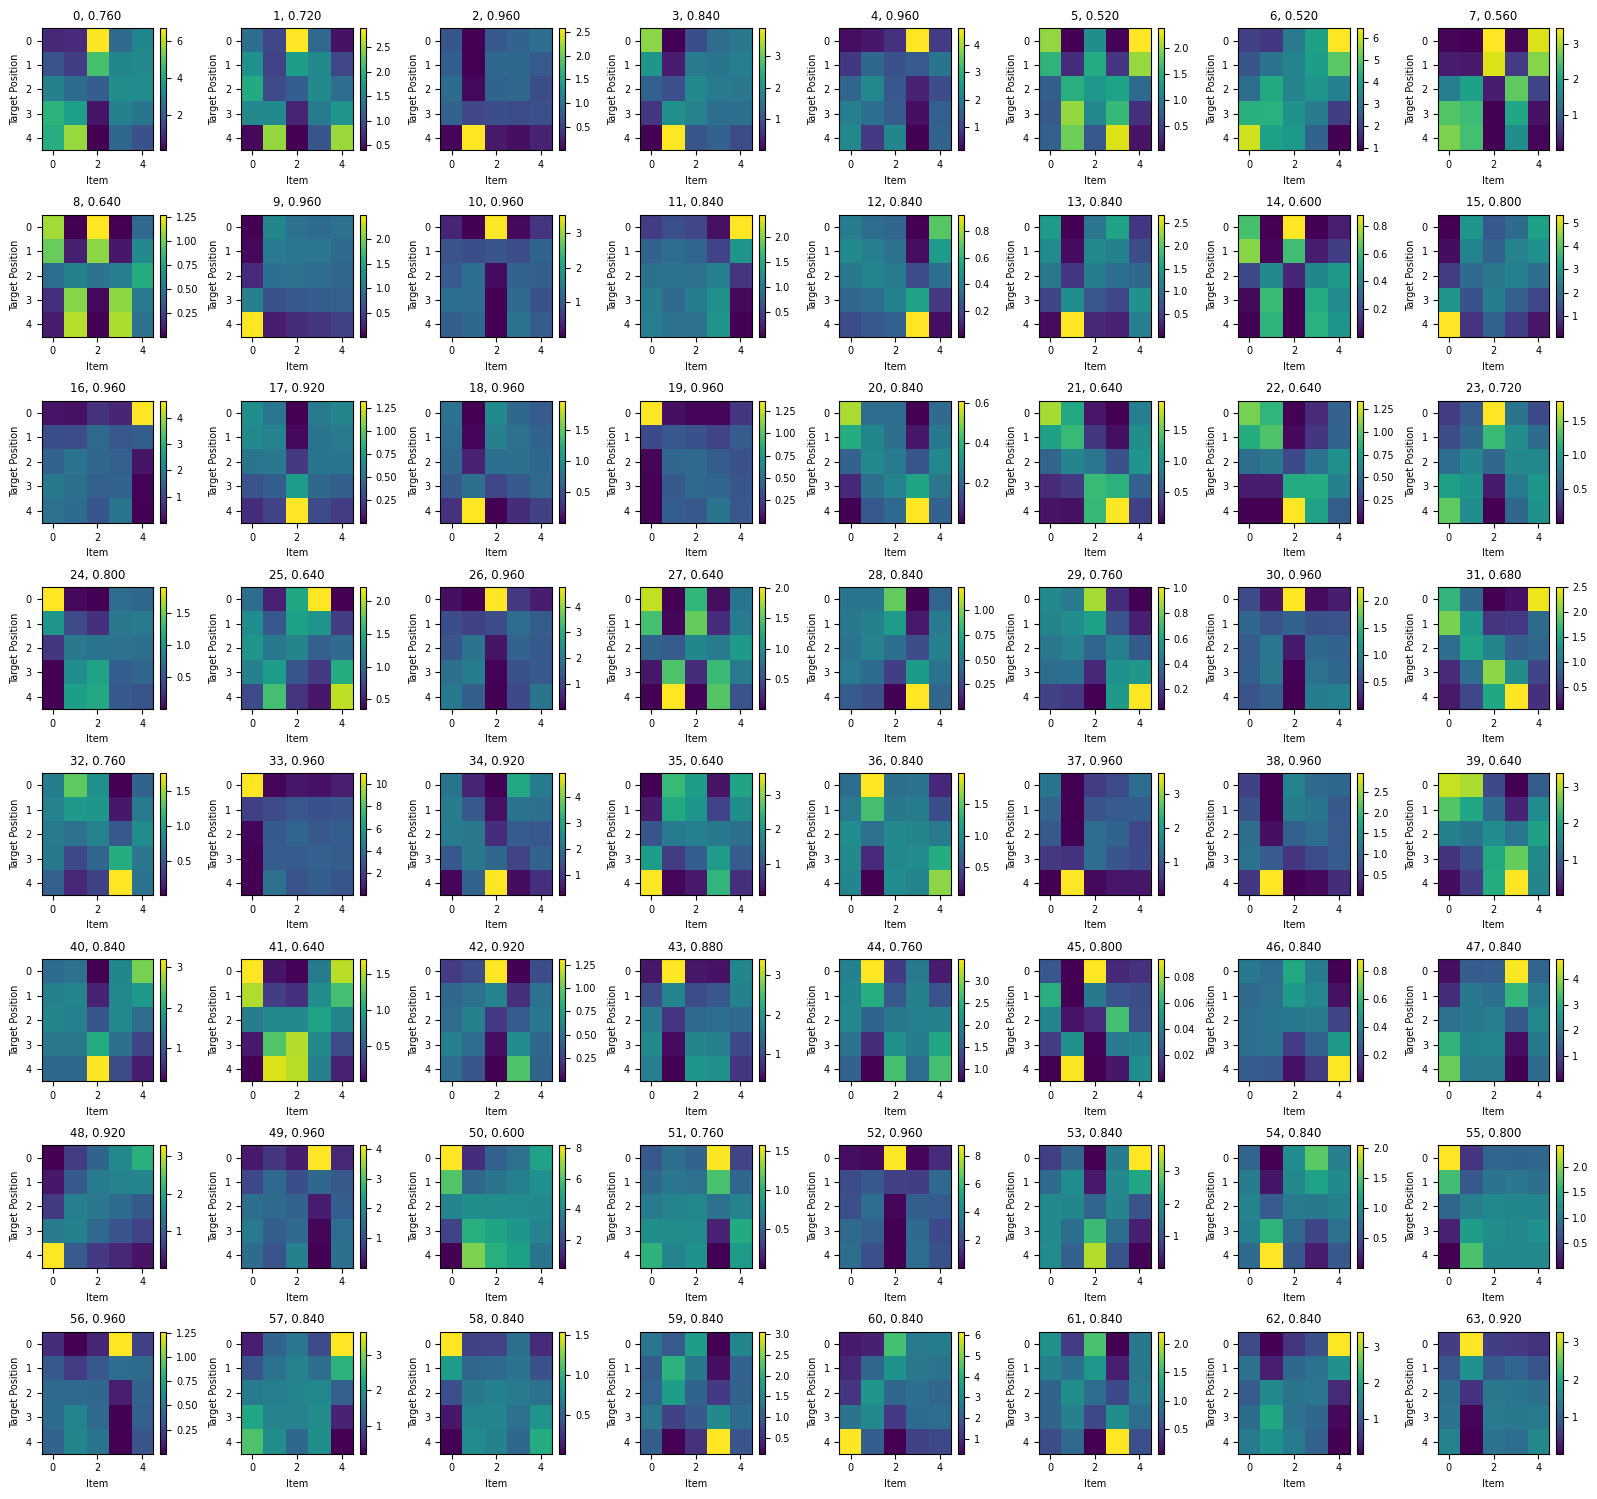

Simple:


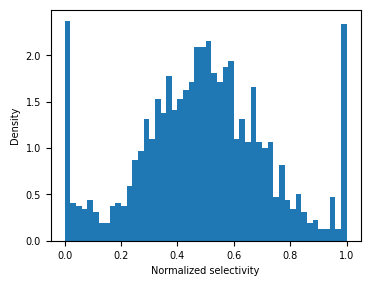

specificity_index: 0.515625 +- 0.27740919122300184


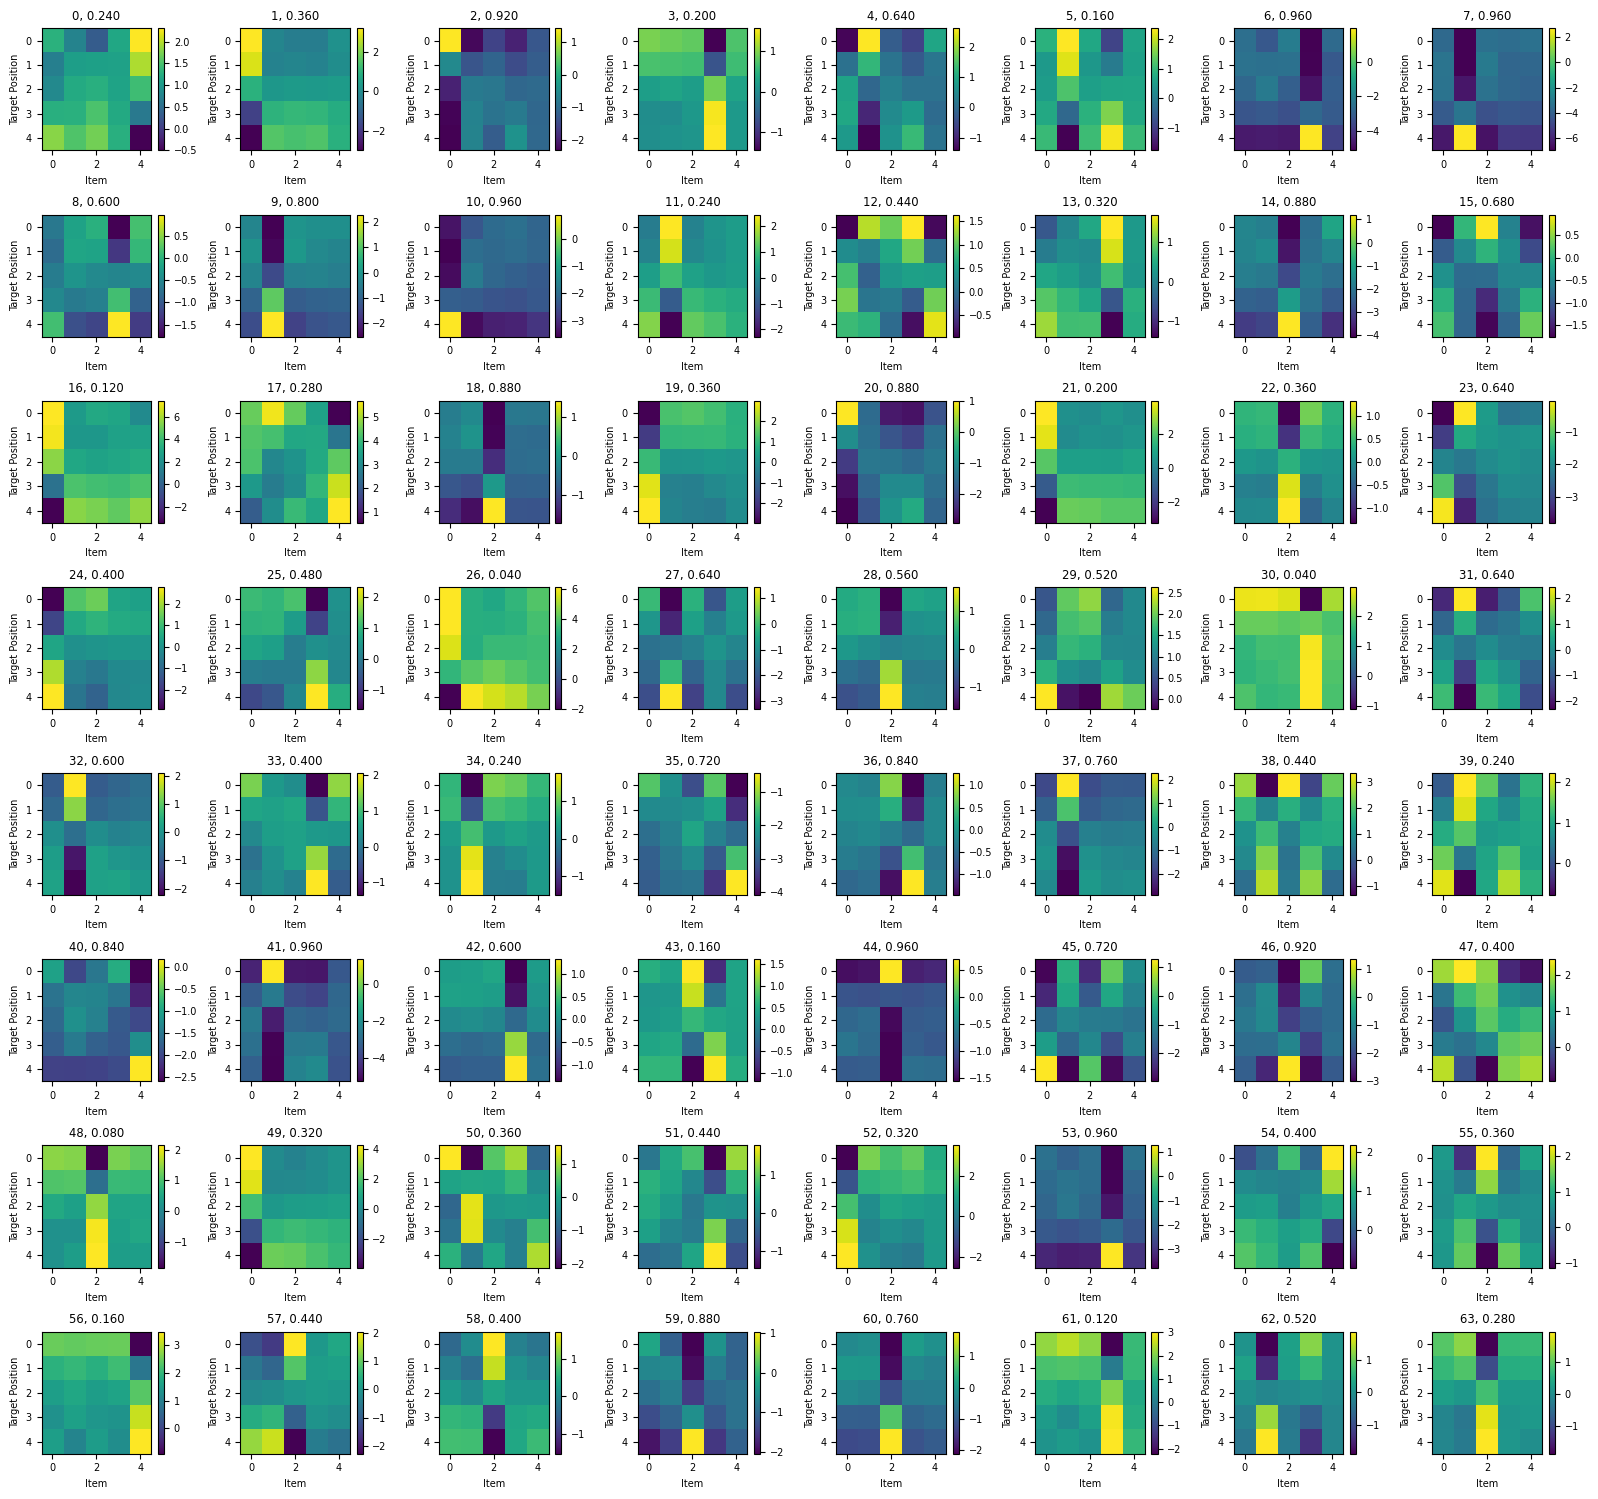

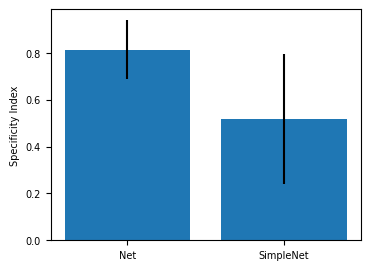

In [ ]:
def cal_specificity_index(target_selectivity):
    # x = torch.FloatTensor(target_selectivity.reshape(-1, hidden_size)).transpose(1,0)
    # dist = F.softmax(x, dim=-1)
    # entropy = - (dist * F.log_softmax(x, dim=-1)).sum(-1)
    x = target_selectivity.reshape(-1, hidden_size)
    normalized_x = (x - x.min(0))/(x.max(0) - x.min(0) + 1e-10)
    specificity_index = np.where(normalized_x<=0.5,1,0).mean(0)

    fig, ax = plt.subplots(figsize=(4,3))
    ax.hist(normalized_x.reshape(-1), bins=50, density=True)
    ax.set_xlabel('Normalized selectivity')
    ax.set_ylabel('Density')
    plt.show()
    plt.close()
    return specificity_index
def plot_target_selectivity(h_all):
    target_selectivity = np.zeros((seq_len, seq_len, hidden_size))
    for i in range(seq_len):
        for j in range(seq_len):
            target_selectivity[i, j] = h_all[target_all[:, i]==j, -1].mean(0)/h_all.var(axis=(0,1)) #是否要对时间步进行平均？
            # target_selectivity[i, j] = h_all[target_all[:, i]==j].mean(0).var(0)
            # target_selectivity[i, j] = h_all[target_all[:, i]==j].var(0).mean(0)
    specificity_index = cal_specificity_index(target_selectivity)
    fig, ax = plt.subplots(8,8, figsize=(16,15))
    ax = ax.flatten()
    for k in range(hidden_size):
        im = ax[k].imshow(target_selectivity[...,k], aspect='auto', cmap='viridis')
        fig.colorbar(im, ax=ax[k])
        ax[k].set_ylabel('Target Position')
        ax[k].set_xlabel('Item')
        ax[k].set_title(f'{k}, {specificity_index[k]:.3f}')
    print('specificity_index:', specificity_index.mean(), '+-', specificity_index.std())
    plt.tight_layout()
    plt.show()
    plt.close()
    return specificity_index
print('Net:')
s_index_all = plot_target_selectivity(h_all)
print('Simple:')
s_index_simple = plot_target_selectivity(h_simple)

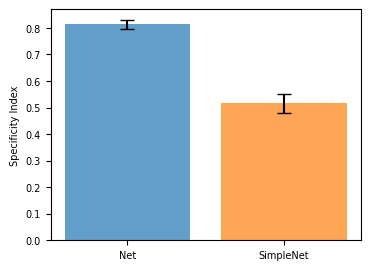

In [31]:
fig, ax = plt.subplots(1,1, figsize=(4,3))
mean_net = s_index_all.mean()
std_net = s_index_all.std()/np.sqrt(len(s_index_all))
mean_simple = s_index_simple.mean()
std_simple = s_index_simple.std()/np.sqrt(len(s_index_simple))
ax.bar([0,1], [mean_net, mean_simple], yerr=[std_net, std_simple], tick_label=['Net', 'SimpleNet'],
       color=['C0', 'C1'], alpha=0.7, capsize=5)
ax.set_ylabel('Specificity Index')
plt.show()
plt.close()

Net:


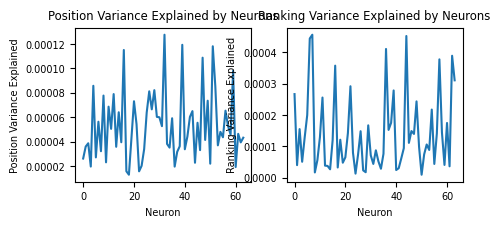

Position selective neurons: [32 39 51 16 47]
Ranking selective neurons: [ 7 44  6 36 62]
Item 0 specific neurons: [ 9 55 58 19 50] 0.109375
Item 1 specific neurons: [63  2 54 36 18] 0.125
Item 2 specific neurons: [17 10 23 30 40] 0.109375
Item 3 specific neurons: [51 49 56 32 28] 0.109375
Item 4 specific neurons: [57 11 46 16 62] 0.0625


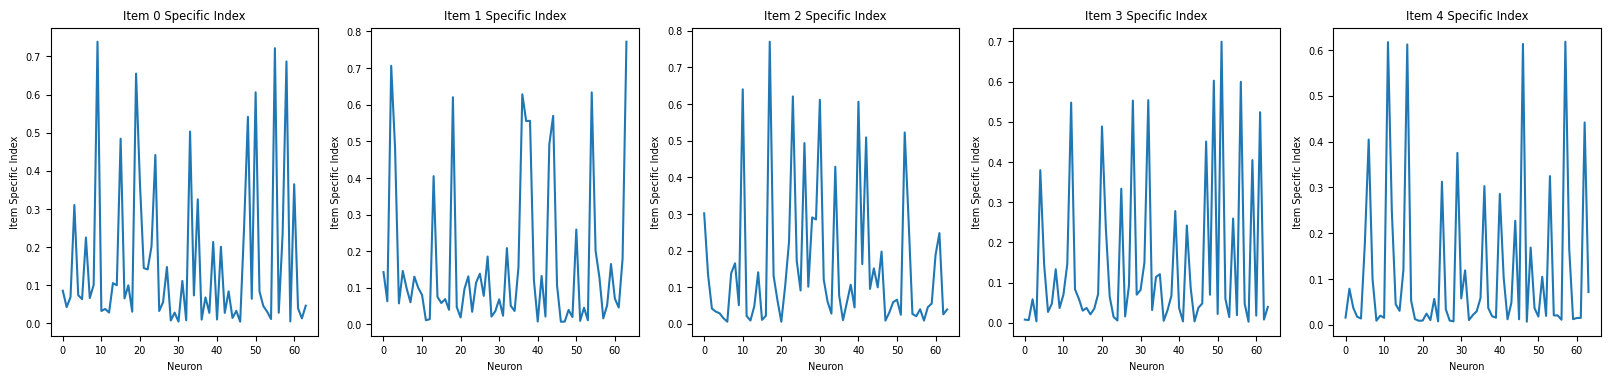

Simple:


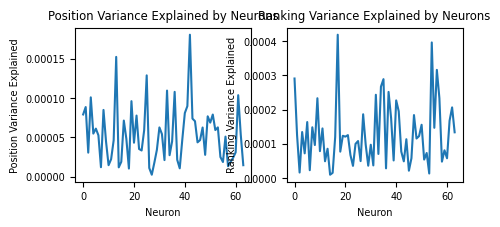

Position selective neurons: [42 13 25 33 36]
Ranking selective neurons: [17 54 56  0 35]
Item 0 specific neurons: [21 19 49  1 24] 0.171875
Item 1 specific neurons: [32 37  9 34 11] 0.203125
Item 2 specific neurons: [60 58 48 63 22] 0.21875
Item 3 specific neurons: [42  3 53 61 13] 0.1875
Item 4 specific neurons: [56 54  0 40 35] 0.09375


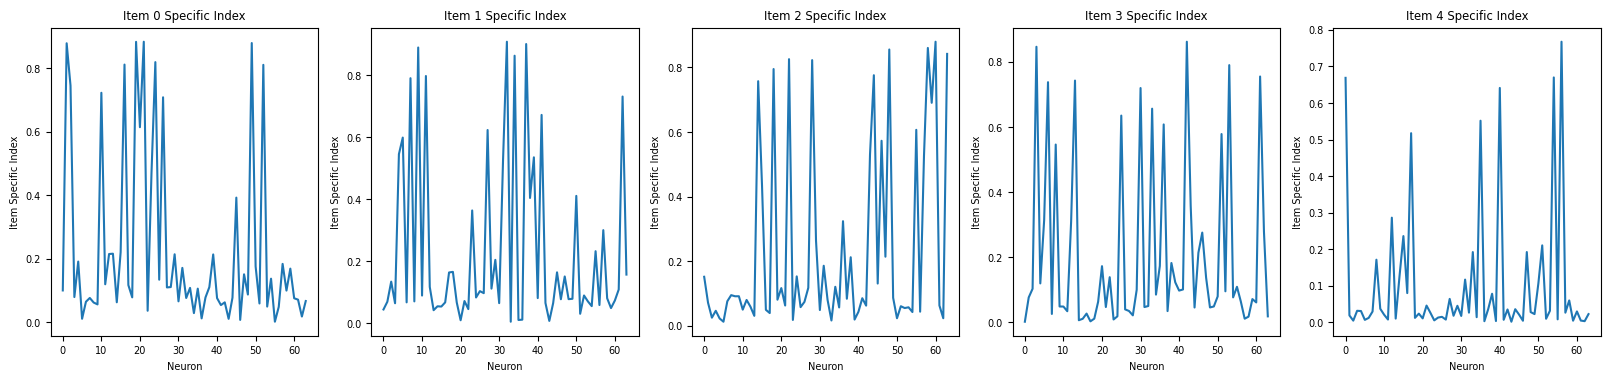

In [7]:
def plot_item_ranking_index(h_all):
    item_ranking_mean = np.zeros((seq_len, seq_len, hidden_size))
    for i in range(seq_len):
        for j in range(seq_len):
            item_ranking_mean[i, j] = h_all[target_all[:, i]==j, -1].mean(0)
    ranking_variance_explained = item_ranking_mean.mean(1).var(0)/item_ranking_mean.var(axis=(0,1))
    position_variance_explained = item_ranking_mean.mean(0).var(0)/item_ranking_mean.var(axis=(0,1))
    fig, ax = plt.subplots(1,2, figsize=(5,2))
    ax[0].plot(position_variance_explained)
    ax[0].set_xlabel('Neuron')
    ax[0].set_ylabel('Position Variance Explained')
    ax[0].set_title('Position Variance Explained by Neurons')
    ax[1].plot(ranking_variance_explained)
    ax[1].set_xlabel('Neuron')
    ax[1].set_ylabel('Ranking Variance Explained')
    ax[1].set_title('Ranking Variance Explained by Neurons')
    plt.show()
    plt.close()
    print('Position selective neurons:', np.argsort(-position_variance_explained)[:5])
    print('Ranking selective neurons:', np.argsort(-ranking_variance_explained)[:5])

    item_specific_index = item_ranking_mean.var(0)/h_all[:,-1].var(axis=0)
    fig, ax = plt.subplots(1, 5, figsize=(20,4))
    for i in range(5):
        ax[i].plot(item_specific_index[i])
        ax[i].set_xlabel('Neuron')
        ax[i].set_ylabel('Item Specific Index')
        ax[i].set_title(f'Item {i} Specific Index')
        print(f'Item {i} specific neurons:', np.argsort(-item_specific_index[i])[:5], np.mean(item_specific_index[i]>0.5))
    plt.show()
    plt.close()

print('Net:')
plot_item_ranking_index(h_all)
print('Simple:')
plot_item_ranking_index(h_simple)

In [8]:
# position_i_specific_neurons = np.argsort(-item_specific_index[1])[:5]
# n_trial = 5
# for i in range(n_trial):
#     fig, ax = plt.subplots(1,1, figsize=(4,3))
#     idx = np.random.randint(h_all.shape[0])
#     print('input:', input_all[idx].squeeze(), 'target:', target_all[idx])
#     for j in range(5):
#         ax.plot(h_all[idx, :, position_i_specific_neurons[j]], marker='o', label=position_i_specific_neurons[j])
#     ax.legend()
#     ax.set_xlabel('Time step')
#     ax.set_ylabel('Activity')
#     plt.show()
#     plt.close()

The sequence is sorted step by step


In [9]:
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
def pairwise_decoding_auc(h_all):
    pairs = [(a,b) for a in range(5) for b in range(a+1,5)]
    aucs = []
    for (a,b) in pairs:
        y = (input_all[:, a, 0] < input_all[:, b, 0])  # match batch
        X = h_all[:, -1].reshape(-1, hidden_size)

        clf = LogisticRegression(max_iter=1000)
        clf.fit(X, y)
        p = clf.predict_proba(X)[:,1]
        aucs.append(roc_auc_score(y, p))
    return np.mean(aucs)
print('Pairwise AUC (mean):', 'Net:', pairwise_decoding_auc(h_all), 'Simple:', pairwise_decoding_auc(h_simple))

Pairwise AUC (mean): Net: 0.9998636742863118 Simple: 0.9994902552248472


In [10]:
def argsort_acc_over_time(h_all, input_all):
    accs = np.zeros((seq_len-1, seq_len))
    for i in range(1,seq_len):
        data = input_all[:, :i+1, 0]
        argsort_till_t = data.argsort(1)
        X = h_all[:, i]
        for j in range(i+1):
            y = argsort_till_t[:, j]
            # max_pos_till_t = data.argsort(1)[:,-1]  # get the position of the max number till time t
            # print('max_pos_till_t:', max_pos_till_t)

            clf = LogisticRegression(max_iter=1000)
            clf.fit(X, y)
            p = clf.predict(X)
            accs[i-1, j] = (p == y).mean()
    return accs
acc_all = np.zeros((h_all.shape[0]//batch_size, seq_len-1, seq_len))
acc_simple = np.zeros((h_simple.shape[0]//batch_size, seq_len-1, seq_len))
h_all_batch = h_all.reshape(-1, batch_size, seq_len, hidden_size)
h_simple_batch = h_simple.reshape(-1, batch_size, seq_len, hidden_size)
input_all_batch = input_all.reshape(-1, batch_size, seq_len, input_size)
for i in range(acc_all.shape[0]):
    acc_all[i] = argsort_acc_over_time(h_all_batch[i], input_all_batch[i])
    acc_simple[i] = argsort_acc_over_time(h_simple_batch[i], input_all_batch[i])


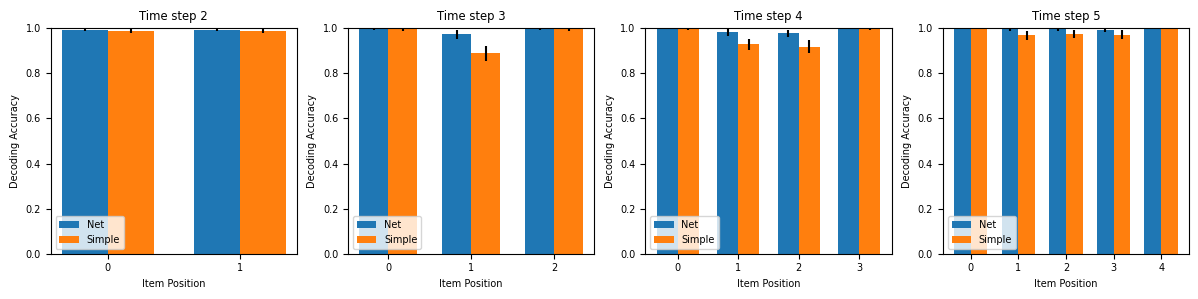

In [11]:
def plot_acc_over_time(acc_all, acc_simple):
    mean_acc_all = acc_all.mean(0)
    std_acc_all = acc_all.std(0)
    mean_acc_simple = acc_simple.mean(0)
    std_acc_simple = acc_simple.std(0)
    fig, ax = plt.subplots(1,seq_len-1, figsize=(3*(seq_len-1),3))
    width = 0.35
    for i in range(seq_len-1):
        ax[i].bar(np.arange(i+2)-width/2, mean_acc_all[i,:i+2], width, yerr=std_acc_all[i,:i+2], label='Net')
        ax[i].bar(np.arange(i+2)+width/2, mean_acc_simple[i,:i+2], width, yerr=std_acc_simple[i,:i+2], label='Simple')
        ax[i].set_ylim(0,1)
        ax[i].set_xticks(np.arange(i+2))
        ax[i].set_xlabel('Item Position')
        ax[i].set_ylabel('Decoding Accuracy')
        ax[i].set_title(f'Time step {i+2}')
        ax[i].legend(loc='lower left')
    plt.tight_layout()
    plt.show()
    plt.close()
plot_acc_over_time(acc_all, acc_simple)

In [12]:
print('input_all shape:', input_all.shape)

input_all shape: (6400, 5, 1)


Epoch 0, CE Loss: 1.6139
Accuracy: 0.2721
Epoch 1000, CE Loss: 0.5368
Accuracy: 0.7975
Epoch 2000, CE Loss: 0.3793
Accuracy: 0.8539
Epoch 3000, CE Loss: 0.3113
Accuracy: 0.8791
Epoch 4000, CE Loss: 0.2802
Accuracy: 0.8898
Epoch 5000, CE Loss: 0.2627
Accuracy: 0.8969
Epoch 6000, CE Loss: 0.2716
Accuracy: 0.9029
Epoch 7000, CE Loss: 0.2372
Accuracy: 0.9051
Epoch 8000, CE Loss: 0.2146
Accuracy: 0.9082
Epoch 9000, CE Loss: 0.2993
Accuracy: 0.9109
Epoch 0, CE Loss: 1.6329
Accuracy: 0.1665
Epoch 1000, CE Loss: 0.4463
Accuracy: 0.8372
Epoch 2000, CE Loss: 0.2892
Accuracy: 0.8913
Epoch 3000, CE Loss: 0.2437
Accuracy: 0.9072
Epoch 4000, CE Loss: 0.2482
Accuracy: 0.9179
Epoch 5000, CE Loss: 0.2248
Accuracy: 0.9216
Epoch 6000, CE Loss: 0.1728
Accuracy: 0.9273
Epoch 7000, CE Loss: 0.1539
Accuracy: 0.9323
Epoch 8000, CE Loss: 0.1214
Accuracy: 0.9348
Epoch 9000, CE Loss: 0.1779
Accuracy: 0.9352


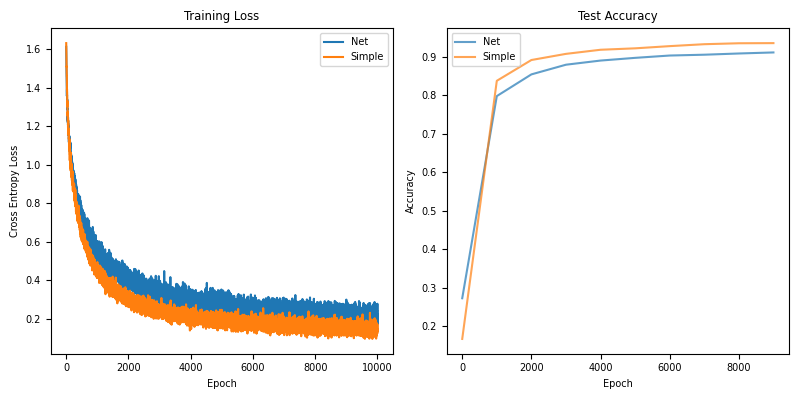

In [13]:
# accs = []
device = 'cuda:0'
argsort_till_t_all = np.zeros((input_all.shape[0], seq_len, seq_len))-1
for i in range(seq_len):
    data = input_all[:, :i+1, 0]
    argsort_till_t = data.argsort(1)
    argsort_till_t_all[:, i, :i+1] = argsort_till_t
class MLP(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, output_dim)
        self.fc2 = nn.Linear(output_dim, output_dim)
    def forward(self, x):
        x = F.tanh(self.fc1(x))
        x = self.fc2(x)
        return x
epoch = 10000
batch_size = 64

def train_argsort_till_t_decoder(h_all):
    mlp = MLP(hidden_size, seq_len**2).to(device)

    optimizer = torch.optim.Adam(mlp.parameters(), lr=1e-3)
    criterion = nn.CrossEntropyLoss(reduction='none')
    shuffled_idxs = np.random.permutation(input_all.shape[0])
    train_idxs = shuffled_idxs[:int(0.8*input_all.shape[0])]
    test_idxs = shuffled_idxs[int(0.8*input_all.shape[0]):]
    losses = np.zeros(epoch)
    accs = np.zeros(epoch//1000)
    for i in range(epoch):
        idxs = train_idxs[np.random.randint(0, train_idxs.shape[0], size=batch_size)]
        X = torch.tensor(h_all[idxs], dtype=torch.float32).to(device) # [batch, seq_len, hidden_size]
        y_origin = torch.tensor(argsort_till_t_all[idxs], dtype=torch.long).to(device) # [batch, seq_len, seq_len]
        predict_distribution = mlp(X).reshape(batch_size, seq_len, seq_len, seq_len).reshape(-1, seq_len)
        target = y_origin.reshape(-1)
        mask = (target != -1)
        ce_loss = criterion(predict_distribution[mask], target[mask]).mean()
        optimizer.zero_grad()
        ce_loss.backward()
        optimizer.step()
        losses[i] = ce_loss.item()
        if i % 1000 == 0:
            print(f'Epoch {i}, CE Loss: {ce_loss.item():.4f}')
            # acc = (predict_distribution.argmax(1) == target)[mask].float().mean().item()
            X = torch.tensor(h_all[test_idxs], dtype=torch.float32).to(device) # [batch, seq_len, hidden_size]
            y_origin = torch.tensor(argsort_till_t_all[test_idxs], dtype=torch.long).to(device) # [batch, seq_len, seq_len]
            predict_distribution = mlp(X).reshape(len(test_idxs), seq_len, seq_len, seq_len).reshape(-1, seq_len)
            target = y_origin.reshape(-1)
            mask = (target != -1)
            acc = (predict_distribution.argmax(1) == target)[mask].float().mean().item()
            accs[i//1000] = acc
            print(f'Accuracy: {acc:.4f}')
    return mlp, losses, accs
mlp_net, loss_net, acc_net = train_argsort_till_t_decoder(h_all)
mlp_simple, loss_simple, acc_simple = train_argsort_till_t_decoder(h_simple)
fig, ax = plt.subplots(1,2, figsize=(8,4))
ax[0].plot(loss_net, label='Net')
ax[0].plot(loss_simple, label='Simple')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Cross Entropy Loss')
ax[0].set_title('Training Loss')
ax[0].legend()
ax[1].plot(np.arange(0, epoch, 1000), acc_net, label='Net', alpha=0.7)
ax[1].plot(np.arange(0, epoch, 1000), acc_simple, label='Simple', alpha=0.7)
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Accuracy')
ax[1].set_title('Test Accuracy')
ax[1].legend()
plt.tight_layout()
plt.show()
plt.close()


input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


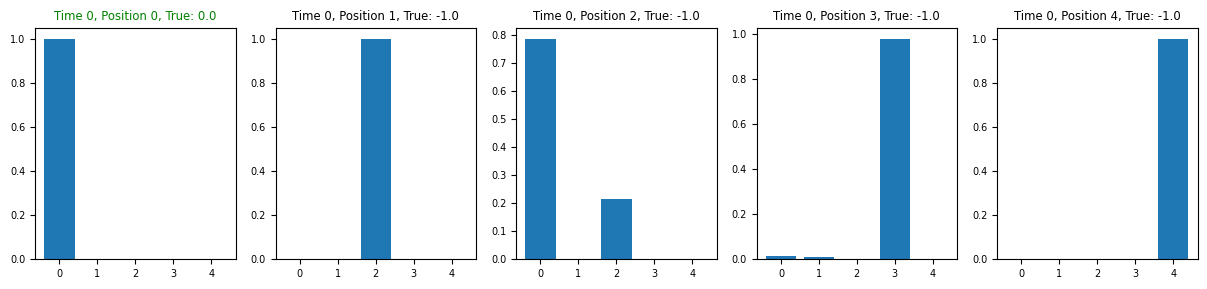

input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


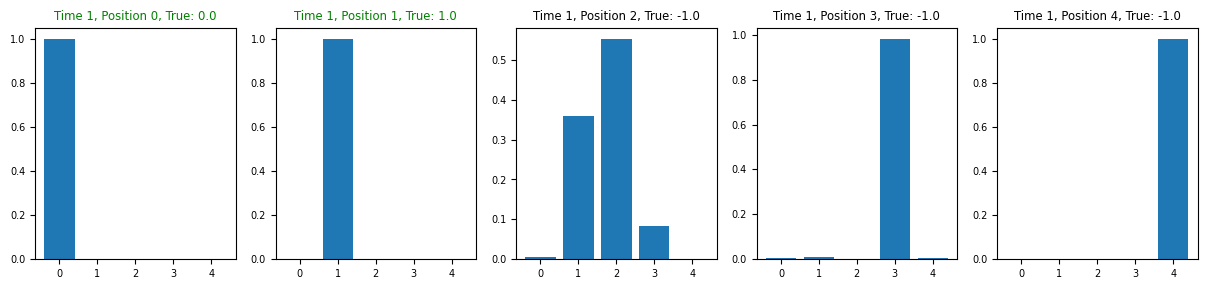

input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


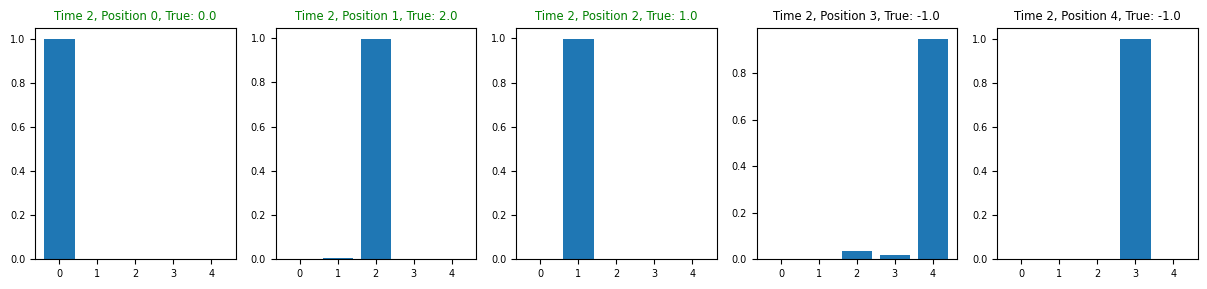

input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


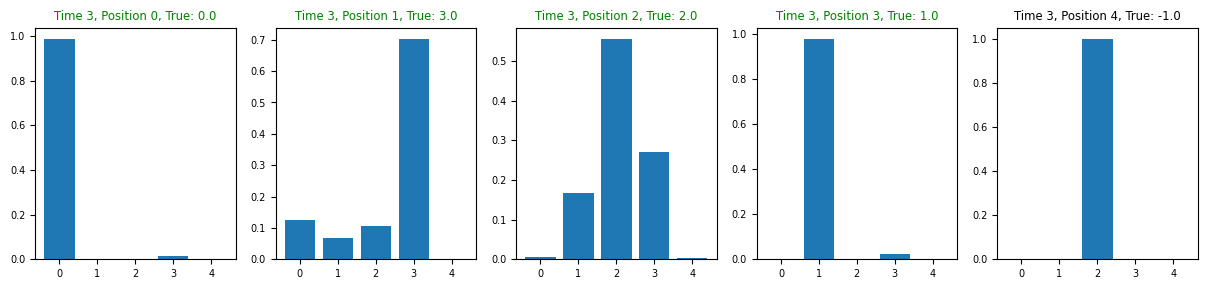

input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


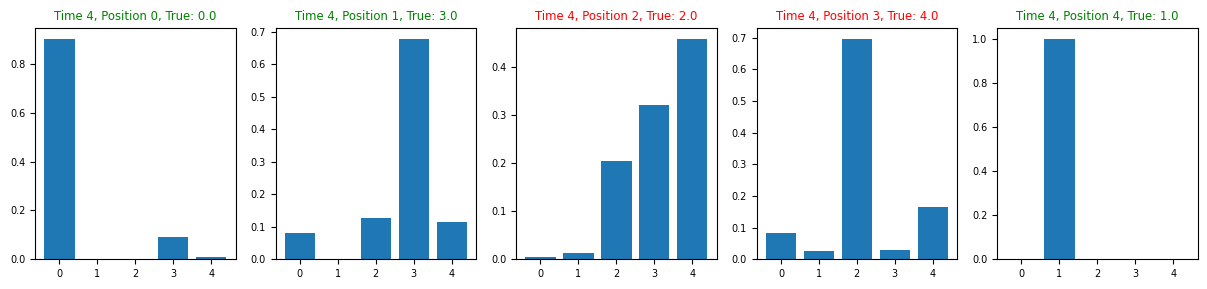

In [14]:
# Test
def test_mlp(mlp, h_all):
    idx = 3523
    x = input_all[idx].squeeze()
    y = target_all[idx]
    argsort_till_t = argsort_till_t_all[idx]
    # print('input:', x, 'target:', y)
    h = torch.tensor(h_all[idx], dtype=torch.float32).to(device) # [seq_len, hidden_size]
    predict_distribution = mlp(h).reshape(seq_len, seq_len, seq_len)
    for i in range(seq_len):
        print('input:', x, 'target:', y)
        fig, ax = plt.subplots(1, seq_len, figsize=(15,3))
        for j in range(seq_len):
            result = F.softmax(predict_distribution[i,j]).detach().cpu().numpy()
            ax[j].bar(np.arange(seq_len), result)
            if (result.argmax() == argsort_till_t[i,j]):
                color = 'green'
            elif argsort_till_t[i,j] == -1:
                color = 'black'
            else:
                color = 'red'
            ax[j].set_title(f'Time {i}, Position {j}, True: {argsort_till_t[i,j]}', color=color)
        plt.show()
        plt.close()
test_mlp(mlp_net, h_all)

input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


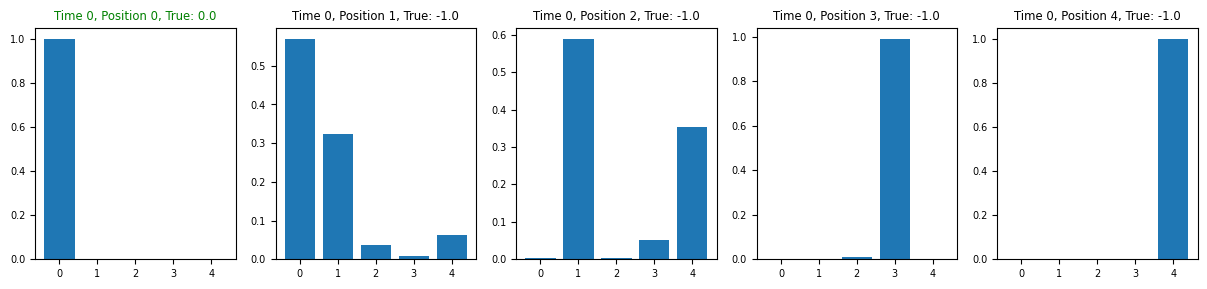

input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


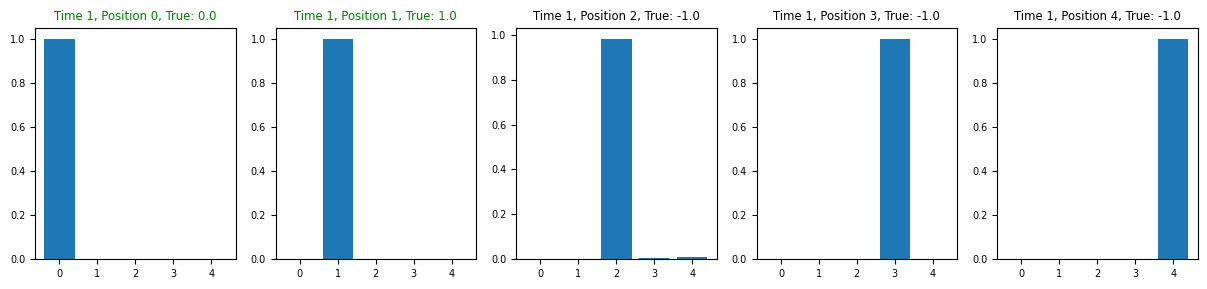

input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


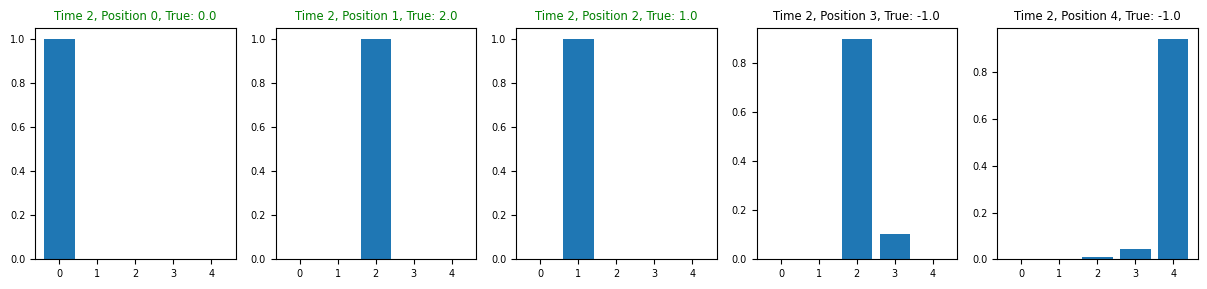

input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


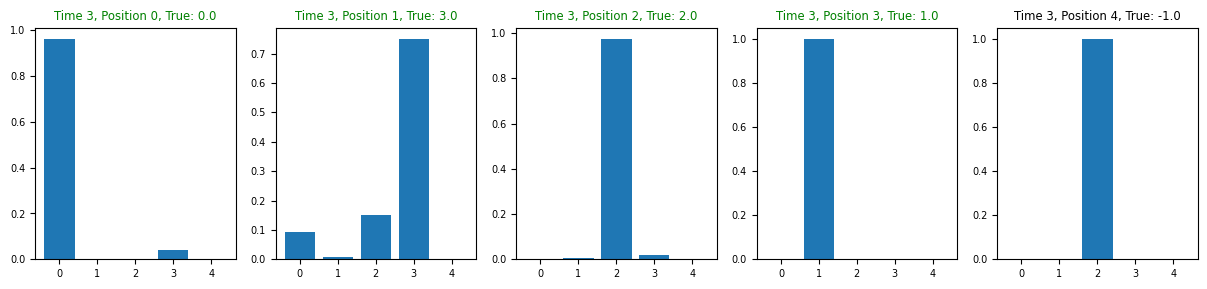

input: [0.350667   0.69172078 0.50482488 0.45496953 0.50970447] target: [0. 3. 2. 4. 1.]


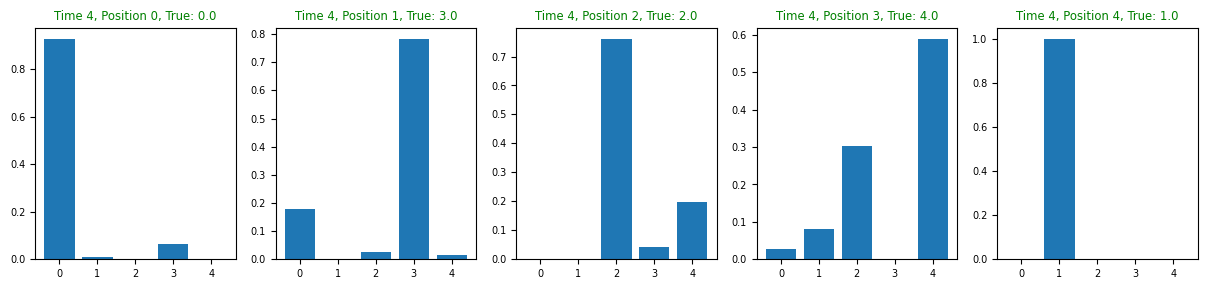

In [15]:
test_mlp(mlp_simple, h_simple)

Manifold


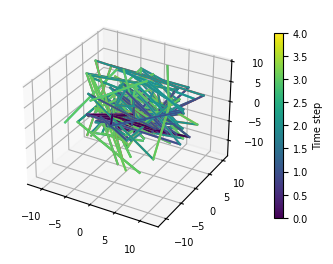

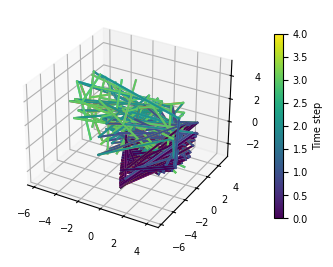

In [16]:
from sklearn.decomposition import PCA
import matplotlib as mpl
%matplotlib inline
# projecting 3d hidden state trajectory
def plot_hidden_traj(h_all, idxs):
    fig = plt.figure(figsize=(4,4))
    ax  = fig.add_subplot(111, projection='3d')
    pca = PCA(n_components=3)
    z = pca.fit_transform(h_all.reshape(-1, hidden_size)).reshape(-1, seq_len, 3)
    cmap = plt.cm.viridis
    norm = mpl.colors.Normalize(vmin=0, vmax=seq_len-1)
    for i in range(50):
        idx = idxs[i]
        ax.plot(z[idx, :, 0], z[idx, :, 1], z[idx, :, 2])
        # create red from light to dark
        c = plt.cm.viridis(np.linspace(0,1,seq_len))
        for j in range(seq_len-1):
            ax.plot(z[idx, j:j+2, 0], z[idx, j:j+2, 1], z[idx, j:j+2, 2], color=cmap(norm(j)))
        #colorbar

    sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])  # 仅用于兼容性
    cbar = fig.colorbar(sm, ax=ax, shrink=0.6, pad=0.1)
    cbar.set_label("Time step")
    plt.show()
    plt.close()
idxs = np.random.randint(0, h_all.shape[0], size=(50,))
plot_hidden_traj(h_all, idxs)
plot_hidden_traj(h_simple, idxs)

hidden state[-1]. No clusters observed


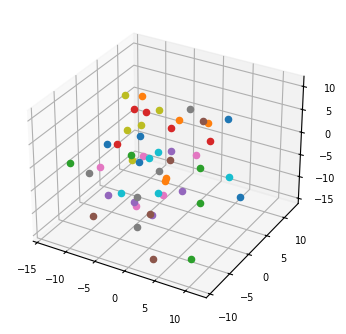

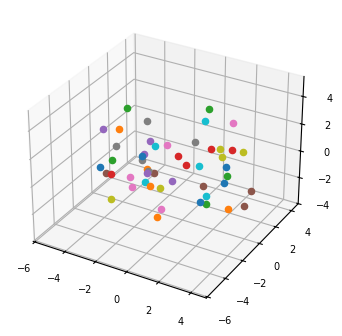

In [17]:
from sklearn.decomposition import PCA
# projecting 3d hidden state trajectory
def plot_last_h(h_all):
    fig = plt.figure(figsize=(4,4))
    ax  = fig.add_subplot(111, projection='3d')
    # fig, ax = plt.subplots(figsize=(4,4))
    pca = PCA(n_components=3)
    z = pca.fit_transform(h_all.reshape(-1, hidden_size)).reshape(-1, seq_len, 3)[:,-1]
    for i in range(50):
        idx = np.random.randint(h_all.shape[0])
        ax.scatter(z[idx, 0], z[idx, 1], z[idx, 2])
    plt.show()
plot_last_h(h_all)
plot_last_h(h_simple)

Eigenvalues and rotating components


Phi: (25600, 66)
res: (64,) 0.1140544290602094
Theta: (66, 64)


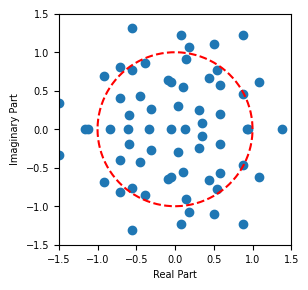

max |eig|: 1.5294797989516498
rotational pairs (angle deg): [54.503004015934565, -54.503004015934565, 167.36408251831028, -167.36408251831028, 113.1173891172674, -113.1173891172674, 29.49636923218938, -29.49636923218938, 65.54159342332255, -65.54159342332255, 86.49466923649743, -86.49466923649743, 143.27274552375002, -143.27274552375002, 80.20549702498577, -80.20549702498577, 131.12621408020271, -131.12621408020271, 27.707116642520603, -27.707116642520603, 54.59769085133094, -54.59769085133094, 81.22957047022807, -81.22957047022807, 114.70842326601245, -114.70842326601245, 126.00265448892931, -126.00265448892931, 44.61039414914837, -44.61039414914837, 56.10881806155991, -56.10881806155991, 150.26354967175993, -150.26354967175993, 162.5398593859966, -162.5398593859966, 136.48293023240882, -136.48293023240882, 97.84956534496385, -97.84956534496385, 94.5678665046247, -94.5678665046247, 79.11012960897006, -79.11012960897006, 138.92802405666725, -138.92802405666725, 18.564437154481453, -18.

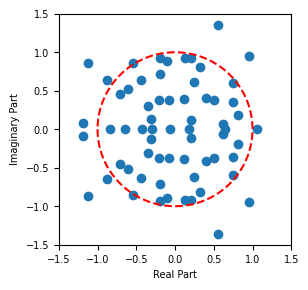

max |eig|: 1.465737359419657
rotational pairs (angle deg): [67.85174860220313, -67.85174860220313, 142.31713318412758, -142.31713318412758, 44.72413523186937, -44.72413523186937, 175.9181395069344, -175.9181395069344, 143.75827356319888, -143.75827356319888, 122.01766518204556, -122.01766518204556, 38.38938096918025, -38.38938096918025, 77.18261547874512, -77.18261547874512, 82.01203896311083, -82.01203896311083, 101.49626467940018, -101.49626467940018, 68.42906465675462, -68.42906465675462, 96.85983660657594, -96.85983660657594, 12.822131265706911, -12.822131265706911, 25.581154118857143, -25.581154118857143, 147.2370839396388, -147.2370839396388, 139.22468482577565, -139.22468482577565, 124.40046039802398, -124.40046039802398, 104.99443845402327, -104.99443845402327, 67.93341444776433, -67.93341444776433, 6.106448376990385, -6.106448376990385, 36.964357202189454, -36.964357202189454, 45.289067318893046, -45.289067318893046, 73.35781822237092, -73.35781822237092, 100.8991272057576, -1

In [18]:
# 组装 (H_t, X_{t+1}) → H_{t+1}
def fit_linear_eigenvalue(h_all):
    H_t   = h_all[:, :-1].reshape(-1, hidden_size)
    H_tp1 = h_all[:, 1: ].reshape(-1, hidden_size)
    # print(H_tp1[:10])
    X_tp1 = input_all[:, 1: ].reshape(-1, input_size)  # 每步输入值的合适编码(如数值/one-hot+pos)

    # 回归: [H_t, X_tp1, 1] * Theta ≈ H_tp1
    Phi = np.hstack([H_t, X_tp1, np.ones((H_t.shape[0], 1))])
    print('Phi:', Phi.shape)  # (time, hidden_size + input_size + 1)
    Theta, res, *_ = np.linalg.lstsq(Phi, H_tp1, rcond=None)
    print('res:', res.shape, np.linalg.norm(res/H_t.shape[0])/(np.linalg.norm(H_tp1,axis=1).mean()))
    print('Theta:', Theta.shape)  # (hidden_size + input_size + 1, hidden_size)
    A = Theta[:hidden_size, :]; B = Theta[hidden_size:-1, :]; c = Theta[-1:, :]

    # 看 A 的特征值
    eigvals = np.linalg.eigvals(A)
    fig, ax = plt.subplots(1,1, figsize=(3,3))
    x = np.real(eigvals)
    y = np.imag(eigvals)
    t = np.linspace(-np.pi, np.pi, 100)
    cost = np.cos(t)
    sint = np.sin(t)
    ax.scatter(x, y)
    ax.plot(cost, sint, 'r--')  # unit circle
    ax.set_xlim(-1.5,1.5)
    ax.set_ylim(-1.5,1.5)
    ax.set_xlabel('Real Part')
    ax.set_ylabel('Imaginary Part')
    plt.show()
    plt.close()
    print('max |eig|:', np.abs(eigvals).max())
    print('rotational pairs (angle deg):', [np.degrees(np.angle(ev)).item() for ev in eigvals if np.imag(ev)!=0])
fit_linear_eigenvalue(h_all)
fit_linear_eigenvalue(h_simple)

In [19]:
def Jacobian(model, h):
    W = model.get_actual_weight().detach().cpu().numpy()
    b = model.lstm.bias.detach().cpu().numpy()
    phi = model.lstm.act

    if isinstance(phi, nn.Softplus):
        phi_prime = lambda x: torch.sigmoid(torch.tensor(x)).numpy()
    elif isinstance(phi, nn.Tanh):
        phi_prime = lambda x: 1 - torch.tanh(torch.tensor(x)).numpy()**2
    z = W @ h + b
    D = np.diag(phi_prime(z))   # tanh: 1 - tanh(z)^2；ReLU: (z>0).float()
    J = D @ W
    return J
def spectrum_summary(net, h_all):
    idx = 86
    h_star = h_all[idx,-2]
    J = Jacobian(net, h_star)
    Jn = J
    # print('Jacobian shape:', Jn.shape)
    eigvals, eigvecs = np.linalg.eig(Jn)
    order = np.argsort(-np.abs(eigvals))
    eigvals = eigvals[order]; eigvecs = eigvecs[:, order]
    lam_max = eigvals[0]
    out = {"top_abs_eig": np.abs(lam_max), "top_eig": lam_max}
    # if v_dir is not None:
    #     v = v_dir / (np.linalg.norm(v_dir) + 1e-12)
    #     # 在特征向量基上找与 v 最对齐的特征模态
    #     cs = np.abs(eigvecs.T @ v)
    #     # print('cosines with v_dir:', cs.shape, cs)
    #     # print('eigvals:', eigvals)
    #     # print('eigvecs:', eigvecs)
    #     j = int(np.argmax(cs))
    #     out.update({
    #         "lam_along_tangent": eigvals[j],
    #         "cos_with_tangent": cs[j],
    #         "max_abs_eig_orth": np.max(np.delete(np.abs(eigvals), j))
    #     })
    return out
# h_star = mA + 0.0*vA
# v_dir  = vA

# 2) 计算 Jacobian 与谱

# alpha=0.8
# Jg = (1-alpha)*torch.eye(J.shape[0], device=J.device) + alpha*J
# eig = np.linalg.eigvals(Jg.cpu().numpy())
# print('rho(Jg)=', np.max(np.abs(eig)))
print(spectrum_summary(net, h_all))
print(spectrum_summary(simple_net, h_simple))

{'top_abs_eig': np.float64(1.7752703772067888), 'top_eig': np.complex128(0.5120170196545472+1.6998304279462733j)}
{'top_abs_eig': np.float64(1.1017596366543325), 'top_eig': np.complex128(-0.08522951702208151+1.0984581131699422j)}


Fixed points (not converged)


In [20]:
# # %matplotlib widget
# %matplotlib inline
# from sklearn.cluster import DBSCAN


# def fixed_point_forward(W, b, phi, u=None, h0=None, alpha=1.0, tol=1e-6, iters=1000):
#     # W: (H,H); b(u): (H,)
#     H = W.shape[0]
#     h = np.zeros(H) if h0 is None else h0.copy()
#     for k in range(iters):
#         z  = W @ h + b if u is None else W @ h + b(u)
#         f  = phi(z)
#         h1 = (1-alpha)*h + alpha*f
#         if np.linalg.norm(h1 - h) < tol * (1 + np.linalg.norm(h)):
#             return h1, k+1, True
#         h = h1
#     return h, iters, False
# def fixed_point(model, h0=None):
#     W = model.get_actual_weight().detach().cpu().numpy()
#     b = model.lstm.bias.detach().cpu().numpy()
#     phi = model.lstm.act
#     if isinstance(phi, nn.Softplus):
#         phi = lambda x: F.softplus(torch.tensor(x)).numpy()
#     fp, k, converged = fixed_point_forward(W, b, phi, alpha=0.8, h0=h0)
#     return fp, k, converged
# n_fp = 200
# fp_all = np.zeros((n_fp, hidden_size))
# target_fpall = np.zeros((n_fp, seq_len))
# input_fpall = np.zeros((n_fp, seq_len, input_size))
# for i in range(n_fp):
#     idx = np.random.randint(h_all.shape[0])
#     h0 = h_all[idx, -1]
#     fp, k, converged = fixed_point(net, h0)
#     fp_all[i] = fp
#     target_fpall[i] = target_all[idx]
#     input_fpall[i] = input_all[idx]
# fp_reduced = PCA(n_components=3).fit_transform(fp_all)
# fig = plt.figure(figsize=(4,4))
# ax  = fig.add_subplot(111, projection='3d')

# db = DBSCAN(eps=0.000001, min_samples=10).fit(fp_all)
# labels = db.labels_
# ax.scatter(fp_reduced[:,0], fp_reduced[:,1], fp_reduced[:,2], c=labels)
# print(np.unique(labels, return_counts=True))
# plt.show()

In [21]:
# attractor_points_A = fp_all[labels==0]
# attractor_points_B = fp_all[labels==1]
# print('Cluster A size:', len(attractor_points_A), 'Cluster B size:', len(attractor_points_B))
# def line_dim(points):
#     u, s, _ = np.linalg.svd(points - points.mean(0), full_matrices=False)
#     return s[0]**2 / (s**2).sum(), s[:3]  # 主成分占比与奇异值

# # 2) 主方向
# def line_direction(points):
#     u, s, vh = np.linalg.svd(points - points.mean(0), full_matrices=False)
#     print('line_dim:', line_dim(points))
#     return points.mean(0), vh[0]  # (m, v)

# mA, vA = line_direction(attractor_points_A)
# mB, vB = line_direction(attractor_points_B)

# # 3) 原空间最小距离
# def skew_distance(mA, vA, mB, vB):
#     # 解 min_{a,b} || (mA + a vA) - (mB + b vB) ||
#     A = np.stack([vA, -vB], axis=1)   # H x 2
#     rhs = (mB - mA)
#     sol, *_ = np.linalg.lstsq(A, rhs, rcond=None)
#     a, b = sol
#     d = np.linalg.norm((mA + a*vA) - (mB + b*vB))
#     return d, a, b

# dmin, a, b = skew_distance(mA, vA, mB, vB)
# # print('line A direction:', vA, 'line B direction:', vB)
# print('min distance between lines (orig space):', dmin)
# print('norm of hidden state:', np.linalg.norm(mA), np.linalg.norm(mB))

In [22]:
def Jacobian(model, h):
    W = model.get_actual_weight().detach().cpu().numpy()
    b = model.lstm.bias.detach().cpu().numpy()
    phi = model.lstm.act
    if isinstance(phi, nn.Softplus):
        phi_prime = lambda x: torch.sigmoid(torch.tensor(x)).numpy()
    z = W @ h + b
    D = np.diag(phi_prime(z))   # tanh: 1 - tanh(z)^2；ReLU: (z>0).float()
    J = D @ W
    return J
def spectrum_summary(J, v_dir=None):
    Jn = J
    # print('Jacobian shape:', Jn.shape)
    eigvals, eigvecs = np.linalg.eig(Jn)
    order = np.argsort(-np.abs(eigvals))
    eigvals = eigvals[order]; eigvecs = eigvecs[:, order]
    lam_max = eigvals[0]
    out = {"top_abs_eig": np.abs(lam_max), "top_eig": lam_max}
    if v_dir is not None:
        v = v_dir / (np.linalg.norm(v_dir) + 1e-12)
        # 在特征向量基上找与 v 最对齐的特征模态
        cs = np.abs(eigvecs.T @ v)
        # print('cosines with v_dir:', cs.shape, cs)
        # print('eigvals:', eigvals)
        # print('eigvecs:', eigvecs)
        j = int(np.argmax(cs))
        out.update({
            "lam_along_tangent": eigvals[j],
            "cos_with_tangent": cs[j],
            "max_abs_eig_orth": np.max(np.delete(np.abs(eigvals), j))
        })
    return out
# h_star = mA + 0.0*vA
# v_dir  = vA

# 2) 计算 Jacobian 与谱
J = Jacobian(net, h_star)
# alpha=0.8
# Jg = (1-alpha)*torch.eye(J.shape[0], device=J.device) + alpha*J
# eig = np.linalg.eigvals(Jg.cpu().numpy())
# print('rho(Jg)=', np.max(np.abs(eig)))
info = spectrum_summary(J)
print(info)

NameError: name 'h_star' is not defined

In [ ]:
h_star = mB + 0.0*vB
v_dir  = vB
J = Jacobian(net, h_star)
alpha=0.8
Jg = (1-alpha)*torch.eye(J.shape[0], device=J.device) + alpha*J
eig = np.linalg.eigvals(Jg.cpu().numpy())
print('rho(Jg)=', np.max(np.abs(eig)))
info = spectrum_summary(J, v_dir=v_dir)
print(info)

rho(Jg)= 0.9220650104772509
{'top_abs_eig': np.float64(1.0504727331125387), 'top_eig': np.complex128(0.32490120148998447+0.9989655510993817j), 'lam_along_tangent': np.complex128(0.32490120148998447+0.9989655510993817j), 'cos_with_tangent': np.float64(0.671973989044756), 'max_abs_eig_orth': np.float64(1.0504727331125387)}
